# Planning a trajectory with a factor graph

A cart at rest has 1.8 seconds to reach a point one metre away and stop. A factor graph sets the price of missing the goal and the cost of acceleration. We combine it with a dynamics function, a Gaussian proposal, and an MPPI update, then examine how the same control sequence behaves under two models of motion.

GTSAM Copyright 2010-2026, Georgia Tech Research Corporation,
Atlanta, Georgia 30332-0415

All Rights Reserved

Authors: Akash Ratheesh and Frank Dellaert (see THANKS for the full author list)

See LICENSE for the license information

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/borglab/gtsam/blob/develop/gtsam/planning/doc/SamplingPlanner.ipynb)

In [1]:
try:
    import google.colab
    %pip install --quiet gtsam-develop plotly==6.3.1
except ImportError:
    pass

In [2]:
from html import escape
import numpy as np
import gtsam
from gtsam.symbol_shorthand import U, X
from plotly.subplots import make_subplots
from IPython.display import HTML, display

teal, orange, slate = "#087B78", "#B65025", "#536577"
plotly_js = "https://cdn.plot.ly/plotly-3.1.1.min.js"

## Describe the objective on a horizon

At step $k$ the state is $x_k=[p_k,v_k]$ and the control is the scalar acceleration $u_k$. The twelve controls have keys $U(0),\ldots,U(11)$ and the thirteen states have keys $X(0),\ldots,X(12)$. The terminal prior specifies arrival and stopping tolerances. A prior on each control assigns a cost to sustained acceleration. Every prior contributes half the squared, whitened residual to the graph error.

In [3]:
H, dt = 12, 0.15
state_keys = [X(k) for k in range(H + 1)]
control_keys = [U(k) for k in range(H)]
goal = np.array([1., 0.])
graph = gtsam.NonlinearFactorGraph()
terminal = gtsam.noiseModel.Diagonal.Sigmas(np.array([0.06, 0.12]))
effort = gtsam.noiseModel.Isotropic.Sigma(1, 4.)
graph.add(gtsam.PriorFactorVector(state_keys[-1], goal, terminal))
for key in control_keys:
    graph.add(gtsam.PriorFactorVector(key, np.zeros(1), effort))

## Supply a vector field and solve

The field returns a derivative, $f(x,u)=[v,u]$. A planner step uses $x_{k+1}=\operatorname{Retract}_{x_k}(\Delta t\,f(x_k,u_k))$. For this Euclidean state, retraction is addition. The planner writes each predicted state and applied control into `Values` at the specified keys. Starting from zero controls, each iteration draws a batch from the Gaussian proposal, scores the trajectories with the graph, and lets MPPI update the mean controls.

In [4]:
def vector_field(state, control):
    return np.array([state[1], control[0]])

planner = gtsam.SamplingPlannerVectorVector(state_keys, control_keys, dt)
seed = gtsam.Values()
seed.insert(X(0), np.zeros(2))
initial = planner.rollout(seed, np.zeros((1, H)), vector_field)
proposal = gtsam.GaussianProposal(np.array([[1.5**2]]), 256, 42)
rule = gtsam.MPPI(1.0)
plan = planner.optimize(graph, initial, vector_field, proposal, rule, 12)
controls = planner.nominalControls(plan)
print(f"Graph error {graph.error(initial):.3f} → {graph.error(plan):.3f}")
print(f"Final position {plan.atVector(X(H))[0]:.3f} m, "
      f"velocity {plan.atVector(X(H))[1]:.3f} m/s")

Graph error 138.889 → 0.570
Final position 0.986 m, velocity 0.015 m/s


## Supply a discrete state transition

For a constant acceleration over one interval, the exact position increment is $v\Delta t+\tfrac12u\Delta t^2$. A discrete function returns the full next state, including this term. Wrapping the function with `discreteTransition` tells the planner to take that state as its prediction. We replay the optimized commands without resampling, so any change in position comes entirely from the integration model. The transition can also be passed to `optimize` when it is the planning model.

In [5]:
def constant_acceleration(state, control):
    position, velocity = state
    acceleration = control[0]
    return np.array([position + dt * velocity + 0.5 * dt**2 * acceleration,
                     velocity + dt * acceleration])

discrete = gtsam.discreteTransition(constant_acceleration)
replay = planner.rollout(seed, controls, discrete)
time = dt * np.arange(H + 1)
field_states = np.array([plan.atVector(key) for key in state_keys])
exact_states = np.array([replay.atVector(key) for key in state_keys])
np.testing.assert_allclose(field_states[:, 1], exact_states[:, 1])

The two position traces use the same interval accelerations. Their separation grows while the cart accelerates and shrinks as it slows down. Hover over a time to compare the positions. Interactive figures require an internet connection.

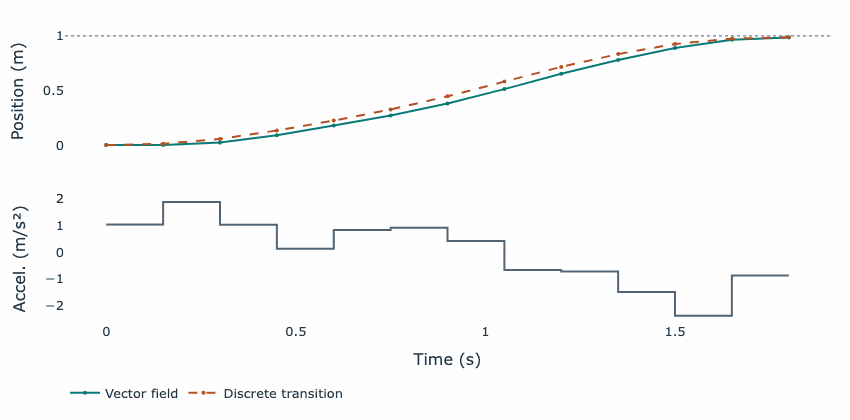

In [6]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.14)
for states, name, color, dash in [(field_states, "Vector field", teal, "solid"),
                                  (exact_states, "Discrete transition", orange, "dash")]:
    fig.add_scatter(x=time, y=states[:, 0], name=name, mode="lines+markers",
                    line=dict(color=color, dash=dash), marker=dict(size=4), row=1, col=1)
fig.add_hline(y=goal[0], line=dict(color=slate, dash="dot", width=1), row=1, col=1)
fig.add_scatter(x=time, y=np.r_[controls[0], controls[0, -1]], name="Acceleration",
                mode="lines", line=dict(color=slate, shape="hv"), showlegend=False, row=2, col=1)
fig.update_yaxes(title_text="Position (m)", row=1, col=1)
fig.update_yaxes(title_text="Accel. (m/s²)", row=2, col=1)
fig.update_xaxes(title_text="Time (s)", row=2, col=1)
fig.update_layout(template="plotly_white", height=420, margin=dict(l=65, r=20, t=28, b=65),
                  font=dict(size=13, color="#243744"), hoverlabel=dict(namelength=-1),
                  legend=dict(orientation="h", y=-0.19, x=0))
# Give Plotly its own document so the figure also runs in the published guide.
plot = fig.to_html(full_html=False, include_plotlyjs=plotly_js,
                   config={"displaylogo": False, "responsive": True})
document = '<!doctype html><meta charset="utf-8"><style>body{margin:0}</style>' + plot
display(HTML(f'<iframe title="Planning a trajectory with a factor graph" style="width:100%;border:0" '
             f'height="{fig.layout.height}" srcdoc="{escape(document, quote=True)}"></iframe>'))

The Gaussian proposal determines which control sequences the graph evaluates. MPPI determines how strongly each of those scores influences the next mean. [Inspect the proposal and a single MPPI update](MPPI.ipynb)